--- Vehicle Dataset ---
   Fuel_Efficiency  Engine_Power  Vehicle_Weight  Engine_Size  Acceleration
0               15           120            1500          2.0           9.5
1               18           130            1600          2.2           9.0
2               16           125            1550          2.0           9.2
3               17           115            1480          1.8           9.8
4               95           600            4500          6.5           3.2

Outliers detected in Fuel_Efficiency:
4    95
Name: Fuel_Efficiency, dtype: int64

Outliers detected in Engine_Power:
4    600
Name: Engine_Power, dtype: int64


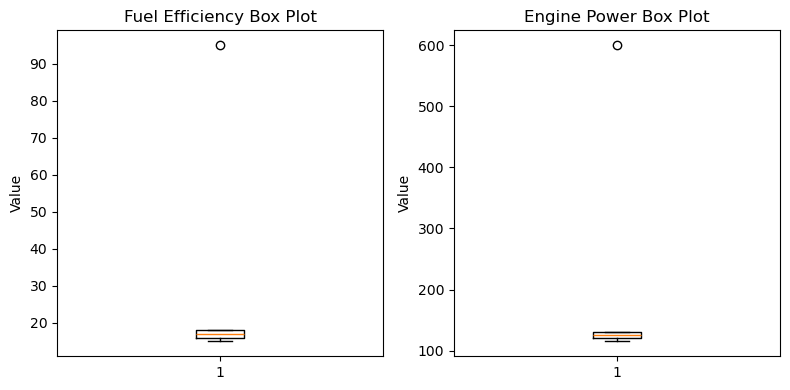

In [28]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Create Vehicle DataFrame with 5 records (including outliers)
data = {
    "Fuel_Efficiency": [15, 18, 16, 17, 95],  # 95 is an outlier
    "Engine_Power": [120, 130, 125, 115, 600],  # 600 is an outlier
    "Vehicle_Weight": [1500, 1600, 1550, 1480, 4500],
    "Engine_Size": [2.0, 2.2, 2.0, 1.8, 6.5],
    "Acceleration": [9.5, 9.0, 9.2, 9.8, 3.2],
}

df = pd.DataFrame(data)
print("--- Vehicle Dataset ---")
print(df)


# 2. IQR Method to Detect and Display Outliers
def detect_outliers(col_name):
  Q1 = df[col_name].quantile(0.25)
  Q3 = df[col_name].quantile(0.75)
  IQR = Q3 - Q1
  lower_bound = Q1 - 1.5 * IQR
  upper_bound = Q3 + 1.5 * IQR

  outliers = df[(df[col_name] < lower_bound) | (df[col_name] > upper_bound)]
  print(f"\nOutliers detected in {col_name}:")
  if not outliers.empty:
    print(outliers[col_name])
  else:
    print("No outliers.")


detect_outliers("Fuel_Efficiency")
detect_outliers("Engine_Power")

# 3. Create Box Plots for Required Columns
plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.boxplot(df["Fuel_Efficiency"])
plt.title("Fuel Efficiency Box Plot")
plt.ylabel("Value")

plt.subplot(1, 2, 2)
plt.boxplot(df["Engine_Power"])
plt.title("Engine Power Box Plot")
plt.ylabel("Value")

plt.tight_layout()
plt.show()

--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   YearsExperience  10 non-null     float64
 1   Salary           10 non-null     int64  
dtypes: float64(1), int64(1)
memory usage: 292.0 bytes
None

Missing Values Count:
YearsExperience    0
Salary             0
dtype: int64

Model Parameters -> Slope (m): 8826.72, Intercept (c): 28264.06
Mean Squared Error (MSE): 57204147.93
Root Mean Squared Error (RMSE): 7563.34


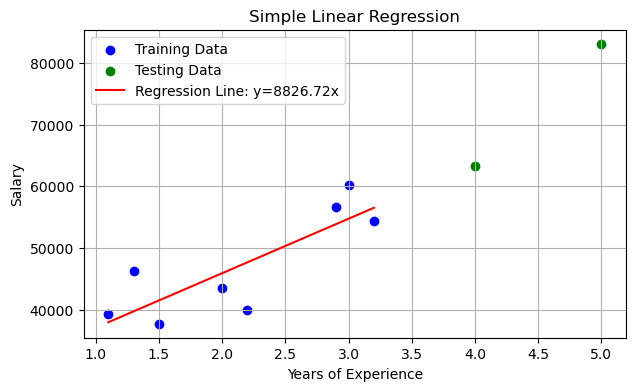

In [29]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Create Salary Dataset
data = {
    "YearsExperience": [1.1, 1.3, 1.5, 2.0, 2.2, 2.9, 3.0, 3.2, 4.0, 5.0],
    "Salary": [39343, 46205, 37731, 43525, 39891, 56642, 60150, 54445, 63218, 83088],
}

df = pd.DataFrame(data)

# 2. Display Info & Check Missing Values
print("--- Dataset Info ---")
print(df.info())
print("\nMissing Values Count:")
print(df.isnull().sum())

# 3. Split Features and Target
X = df["YearsExperience"].values
y = df["Salary"].values

# 4. Manual Train-Test Split (80% Train, 20% Test)
split_idx = int(len(df) * 0.8)
X_train, X_test = X[:split_idx], X[split_idx:]
y_train, y_test = y[:split_idx], y[split_idx:]

# 5. Train Linear Regression Model (Using NumPy Polyfit for m and c)
m, c = np.polyfit(X_train, y_train, 1)
print(f"\nModel Parameters -> Slope (m): {m:.2f}, Intercept (c): {c:.2f}")

# 6. Predict and Evaluate Model
y_pred = m * X_test + c
mse = np.mean((y_test - y_pred) ** 2)
rmse = np.sqrt(mse)

print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")

# 7. Plot Regression Line
plt.figure(figsize=(7, 4))
plt.scatter(X_train, y_train, color="blue", label="Training Data")
plt.scatter(X_test, y_test, color="green", label="Testing Data")
plt.plot(
    X_train, m * X_train + c, color="red", label=f"Regression Line: y={m:.2f}x"
)
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Simple Linear Regression")
plt.legend()
plt.grid(True)
plt.show()

In [30]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Create Heart Disease Dataset
data = {
    "age": [63, 37, 41, 56, 57, 56, 44, 52, 57, 54],
    "sex": [1, 1, 0, 1, 0, 1, 1, 1, 1, 1],
    "cp": [3, 2, 1, 1, 0, 0, 1, 2, 2, 0],
    "trestbps": [145, 130, 130, 120, 120, 140, 120, 172, 150, 140],
    "chol": [233, 250, 204, 236, 354, 192, 226, 199, 168, 239],
    "target": [1, 1, 1, 1, 1, 1, 1, 1, 1, 0],
}

df = pd.DataFrame(data)

# 2. Data Preprocessing (Fill Missing Values)
df.fillna(df.median(), inplace=True)

# 3. Features & Target Split
X = df.drop("target", axis=1).values
y = df["target"].values

# 4. Manual Train-Test Split (70% Train, 30% Test)
split_idx = int(len(df) * 0.7)
X_train, X_test = X[:split_idx], X[split_idx:]
y_train, y_test = y[:split_idx], y[split_idx:]

# 5. Classification Model Training (Using Logistic Regression via NumPy Gradient Descent)
def sigmoid(z):
  return 1 / (1 + np.exp(-np.clip(z, -500, 500)))


X_train_b = np.c_[np.ones((X_train.shape[0], 1)), X_train]
X_test_b = np.c_[np.ones((X_test.shape[0], 1)), X_test]

weights = np.zeros(X_train_b.shape[1])
for _ in range(1000):
  preds = sigmoid(np.dot(X_train_b, weights))
  gradient = np.dot(X_train_b.T, (preds - y_train)) / len(y_train)
  weights -= 0.01 * gradient

# 6. Predictions & Evaluation
test_probs = sigmoid(np.dot(X_test_b, weights))
y_pred = (test_probs >= 0.5).astype(int)

# Calculate Accuracy
accuracy = np.mean(y_pred == y_test)

# Confusion Matrix components
TN = np.sum((y_test == 0) & (y_pred == 0))
FP = np.sum((y_test == 0) & (y_pred == 1))
FN = np.sum((y_test == 1) & (y_pred == 0))
TP = np.sum((y_test == 1) & (y_pred == 1))
cm = np.array([[TN, FP], [FN, TP]])

print(f"Model Accuracy: {accuracy * 100:.2f}%\n")
print("--- Confusion Matrix ---")
print(cm)

Model Accuracy: 66.67%

--- Confusion Matrix ---
[[0 1]
 [0 2]]
